# Donor Retention & Lapse Analysis (Simulated Data)
Synthetic donor database generation and retention analysis in Python.

Run order: Restart & Run All. Output is reproducible only if cells run top to bottom.

## 1. Data Simulation

### 1.1 Setup and Configuration
Imports, constants, and seeded random number generator.

In [25]:
import calendar
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

N_DONORS = 5000
SEED = 42
DATA_DIR = "data"
CHART_DIR = "charts"

rng = np.random.default_rng(SEED)

### 1.2 Donors Table
Generates 5,000 donors with `donor_id`, `donor_type`, and `state`.

In [2]:
donor_ids = [f"D{i:05d}" for i in range(1, N_DONORS + 1)]

donor_types = rng.choice(["Individual", "Corporate"], size=N_DONORS, p=[0.92, 0.08])

states = rng.choice(["CT", "RI", "MA", "NY"], size=N_DONORS, p=[0.50, 0.20, 0.15, 0.15])

donors_df = pd.DataFrame({
    "donor_id": donor_ids,
    "donor_type": donor_types,
    "state": states,
})

print(donors_df.head())
print(donors_df["donor_type"].value_counts())

  donor_id  donor_type state
0   D00001  Individual    CT
1   D00002  Individual    RI
2   D00003  Individual    MA
3   D00004  Individual    CT
4   D00005  Individual    CT
donor_type
Individual    4602
Corporate      398
Name: count, dtype: int64


### 1.3 Gift Date Generator
Samples a gift date with month-weighted seasonality (peak in Nov and Dec).

In [3]:
MONTH_WEIGHTS = {1: .06, 2: .05, 3: .08, 4: .08, 5: .08, 6: .06,
                 7: .05, 8: .05, 9: .06, 10: .08, 11: .12, 12: .23}

def random_date(year):
    """Return a random date in the given year, weighted by MONTH_WEIGHTS."""
    months = list(range(1, 13))
    probs = [MONTH_WEIGHTS[m] for m in months]
    month = int(rng.choice(months, p=probs))
    last_day = calendar.monthrange(year, month)[1]
    day = int(rng.integers(1, last_day + 1))
    return pd.Timestamp(year=year, month=month, day=day)

print(random_date(2023))
print(random_date(2023))

2023-11-07 00:00:00
2023-04-22 00:00:00


### 1.4 Gift Amount Generator
Samples gift size from a lognormal distribution; Corporate gifts are multiplied by 3.

In [4]:
def gift_amount(median, sigma, corporate=False):
    """Return a lognormal gift amount rounded to a realistic value (Corporate x3)."""
    amt = rng.lognormal(mean=np.log(median), sigma=sigma)
    if corporate:
        amt = amt * 3
    if amt < 250:
        amt = max(5, round(amt / 5) * 5)
    else:
        amt = round(amt / 25) * 25
    return float(amt)

print([gift_amount(35, 0.6) for _ in range(5)])
print([gift_amount(1500, 0.7) for _ in range(5)])

[25.0, 50.0, 30.0, 40.0, 20.0]
[2325.0, 475.0, 425.0, 1375.0, 1300.0]


### 1.5 Segment Configuration and Campaign Logic
Latent donor segments (retention rate, gifts per year, gift size) and rule-based campaign labeling.

In [5]:
# Latent donor segments: share of donors, annual retention probability,
# gifts per active year (min, max), gift size median and sigma
SEGMENTS = {
    "one_time":   {"share": 0.55, "retain": 0.05, "gifts": (1, 1), "median": 35,   "sigma": 0.6},
    "occasional": {"share": 0.30, "retain": 0.45, "gifts": (1, 2), "median": 60,   "sigma": 0.6},
    "loyal":      {"share": 0.12, "retain": 0.85, "gifts": (1, 3), "median": 120,  "sigma": 0.5},
    "major":      {"share": 0.03, "retain": 0.90, "gifts": (1, 2), "median": 1500, "sigma": 0.7},
}

REACTIVATION_FACTOR = 0.25
YEARS = [2023, 2024, 2025]
START_YEAR_WEIGHTS = [0.40, 0.33, 0.27]
DISASTER_MONTHS = {(2023, 9), (2024, 10), (2025, 8)}

def pick_campaign(date):
    """Return a campaign label based on the gift date (rule-based with probabilities)."""
    if (date.year, date.month) in DISASTER_MONTHS and rng.random() < 0.7:
        return "Disaster Relief"
    if date.month in (11, 12) and rng.random() < 0.8:
        return "Year-End Appeal"
    if date.month in (3, 4, 5) and rng.random() < 0.6:
        return "Spring Drive"
    return "General Fund"

print(pick_campaign(pd.Timestamp(2023, 12, 10)))
print(pick_campaign(pd.Timestamp(2023, 9, 10)))
print(pick_campaign(pd.Timestamp(2023, 7, 10)))

Year-End Appeal
General Fund
General Fund


### 1.6 Latent Segment and Start-Year Assignment
Assigns each donor a hidden segment and first-gift year. Both are kept out of `donors.csv`.

In [6]:
segment_names = list(SEGMENTS.keys())
segment_probs = [SEGMENTS[s]["share"] for s in segment_names]

donor_segments = rng.choice(segment_names, size=N_DONORS, p=segment_probs)
start_years = rng.choice(YEARS, size=N_DONORS, p=START_YEAR_WEIGHTS)

print(pd.Series(donor_segments).value_counts())
print(pd.Series(start_years).value_counts().sort_index())

one_time      2722
occasional    1555
loyal          587
major          136
Name: count, dtype: int64
2023    1971
2024    1651
2025    1378
Name: count, dtype: int64


### 1.7 Gift Generation Loop
Simulates yearly giving per donor: start year, retention, reactivation, then date, amount, campaign and channel per gift.

In [7]:
CHANNELS = ["Online", "Mail", "Event", "Phone"]
CHANNEL_P = [0.55, 0.25, 0.15, 0.05]

gift_rows = []

for i in range(N_DONORS):
    donor_id = donors_df.loc[i, "donor_id"]
    corporate = donors_df.loc[i, "donor_type"] == "Corporate"
    seg = SEGMENTS[donor_segments[i]]
    start_year = int(start_years[i])
    active_last_year = False

    for year in range(start_year, YEARS[-1] + 1):
        # Giving status: always active in start year, then retention or reactivation
        if year == start_year:
            active = True
        elif active_last_year:
            active = rng.random() < seg["retain"]
        else:
            active = rng.random() < seg["retain"] * REACTIVATION_FACTOR

        if active:
            n_gifts = int(rng.integers(seg["gifts"][0], seg["gifts"][1] + 1))
            for _ in range(n_gifts):
                date = random_date(year)
                gift_rows.append({
                    "donor_id": donor_id,
                    "gift_date": date.date().isoformat(),
                    "amount": gift_amount(seg["median"], seg["sigma"], corporate),
                    "campaign": pick_campaign(date),
                    "channel": str(rng.choice(CHANNELS, p=CHANNEL_P)),
                })

        active_last_year = active

print(len(gift_rows))
print(gift_rows[0])

8816
{'donor_id': 'D00001', 'gift_date': '2025-04-25', 'amount': 50.0, 'campaign': 'General Fund', 'channel': 'Mail'}


### 1.8 Build Gifts Table, Export, and Validation
Builds `gifts_df`, adds `gift_id`, exports both CSVs, and checks totals and year-over-year retention.

In [8]:
gifts_df = pd.DataFrame(gift_rows)
gifts_df = gifts_df.sort_values(["gift_date", "donor_id"]).reset_index(drop=True)
gifts_df.insert(0, "gift_id", [f"G{i:06d}" for i in range(1, len(gifts_df) + 1)])

os.makedirs(DATA_DIR, exist_ok=True)
donors_df.to_csv(f"{DATA_DIR}/donors.csv", index=False)
gifts_df.to_csv(f"{DATA_DIR}/gifts.csv", index=False)
print(f"Saved donors.csv and gifts.csv to {DATA_DIR}")

# Validation
check = gifts_df.copy()
check["year"] = pd.to_datetime(check["gift_date"]).dt.year

print(f"\nDonors: {len(donors_df):,}")
print(f"Gifts: {len(gifts_df):,}")
print(f"Total given: ${gifts_df['amount'].sum():,.0f}")

print("\nGifts and total by year:")
print(check.groupby("year")["amount"].agg(["count", "sum"]).round(0))

print("\nYear-over-year retention:")
by_year = check.groupby("year")["donor_id"].apply(set)
for y in YEARS[:-1]:
    kept = len(by_year[y] & by_year[y + 1]) / len(by_year[y])
    print(f"  {y} -> {y + 1}: {kept:.1%}")

Saved donors.csv and gifts.csv to my_data

Donors: 5,000
Gifts: 8,816
Total given: $1,616,405

Gifts and total by year:
      count       sum
year                 
2023   2523  356625.0
2024   3048  554545.0
2025   3245  705235.0

Year-over-year retention:
  2023 -> 2024: 29.4%
  2024 -> 2025: 37.0%


## 2. Visualization

### 2.1 Load Data
Loads the exported CSVs and creates the `charts` output folder.

In [18]:
gifts = pd.read_csv(f"{DATA_DIR}/gifts.csv", parse_dates=["gift_date"])
gifts["gift_year"] = gifts["gift_date"].dt.year
donors = pd.read_csv(f"{DATA_DIR}/donors.csv")

os.makedirs(CHART_DIR, exist_ok=True)

### 2.2 Cohort Retention Heatmap
Cohort = year of first gift. Each cell is the % of the cohort still giving N years later.

years_since_first      0     1     2
cohort_year                         
2023               100.0  29.4  19.1
2024               100.0  30.8   NaN
2025               100.0   NaN   NaN


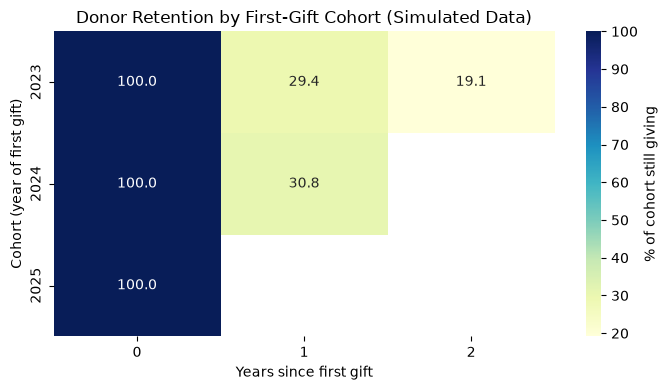

In [19]:
# Cohort = year of each donor's first gift
first_year = gifts.groupby("donor_id")["gift_year"].min().rename("cohort_year")

# One row per donor per year they gave
active = (gifts[["donor_id", "gift_year"]].drop_duplicates()
          .merge(first_year, on="donor_id"))
active["years_since_first"] = active["gift_year"] - active["cohort_year"]

# Donors per cohort per year-since-first, converted to % of cohort
counts = active.pivot_table(index="cohort_year", columns="years_since_first",
                            values="donor_id", aggfunc="nunique")
retention = counts.div(counts[0], axis=0) * 100
print(retention.round(1))

plt.figure(figsize=(7, 4))
sns.heatmap(retention, annot=True, fmt=".1f", cmap="YlGnBu",
            cbar_kws={"label": "% of cohort still giving"})
plt.title("Donor Retention by First-Gift Cohort (Simulated Data)")
plt.xlabel("Years since first gift")
plt.ylabel("Cohort (year of first gift)")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/cohort_retention_heatmap.png", dpi=200)
plt.show()

### 2.3 Giving by Year and Cohort
Total giving per year, stacked by donor cohort (new vs. returning donors).

cohort_year      2023      2024      2025
gift_year                                
2023         356625.0       0.0       0.0
2024         216895.0  337650.0       0.0
2025         171580.0  266350.0  267305.0


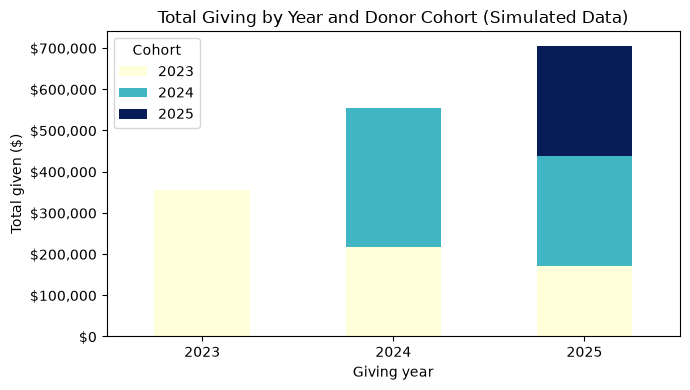

In [20]:
first_year = gifts.groupby("donor_id")["gift_year"].min().rename("cohort_year")
g = gifts.merge(first_year, on="donor_id")

by_year_cohort = (g.pivot_table(index="gift_year", columns="cohort_year",
                                values="amount", aggfunc="sum")
                  .fillna(0))
print(by_year_cohort.round(0))

ax = by_year_cohort.plot(kind="bar", stacked=True, figsize=(7, 4), colormap="YlGnBu")
ax.yaxis.set_major_formatter(lambda x, _: f"${x:,.0f}")
plt.title("Total Giving by Year and Donor Cohort (Simulated Data)")
plt.xlabel("Giving year")
plt.ylabel("Total given ($)")
plt.xticks(rotation=0)
plt.legend(title="Cohort")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/giving_by_year_cohort.png", dpi=200)
plt.show()

### 2.4 Lapsed Donors: Cumulative Share of Giving (Pareto)
Lapsed = gave in 2024, no gift in 2025. Donors ranked by lifetime giving.

Lapsed donors: 1,405
Donors to reach 50% of lapsed giving: 77
Donors to reach 80% of lapsed giving: 441


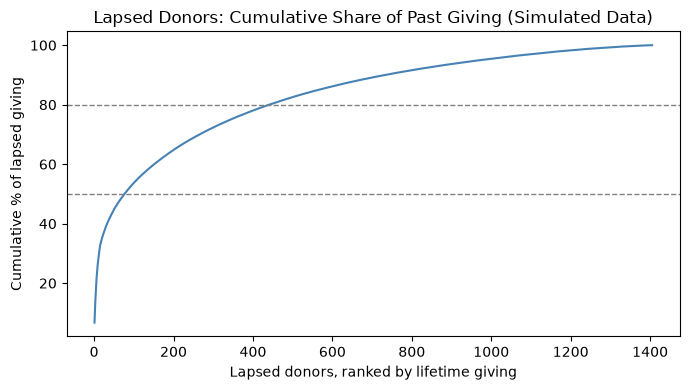

In [21]:
totals = gifts.groupby("donor_id")["amount"].sum()
gave_2024 = set(gifts.loc[gifts["gift_year"] == 2024, "donor_id"])
gave_2025 = set(gifts.loc[gifts["gift_year"] == 2025, "donor_id"])
lapsed_ids = gave_2024 - gave_2025

lapsed = totals[totals.index.isin(lapsed_ids)].sort_values(ascending=False)
cum_pct = lapsed.cumsum() / lapsed.sum() * 100
n50 = int((cum_pct.values >= 50).argmax() + 1)
n80 = int((cum_pct.values >= 80).argmax() + 1)

print(f"Lapsed donors: {len(lapsed):,}")
print(f"Donors to reach 50% of lapsed giving: {n50}")
print(f"Donors to reach 80% of lapsed giving: {n80}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_pct) + 1), cum_pct.values, color="steelblue")
plt.axhline(50, color="gray", linestyle="--", linewidth=1)
plt.axhline(80, color="gray", linestyle="--", linewidth=1)
plt.title("Lapsed Donors: Cumulative Share of Past Giving (Simulated Data)")
plt.xlabel("Lapsed donors, ranked by lifetime giving")
plt.ylabel("Cumulative % of lapsed giving")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/lapsed_cumulative.png", dpi=200)
plt.show()

### 2.5 Giving by Campaign
Total dollars raised per campaign.

campaign
General Fund       866315.0
Year-End Appeal    473775.0
Spring Drive       182260.0
Disaster Relief     94055.0
Name: amount, dtype: float64


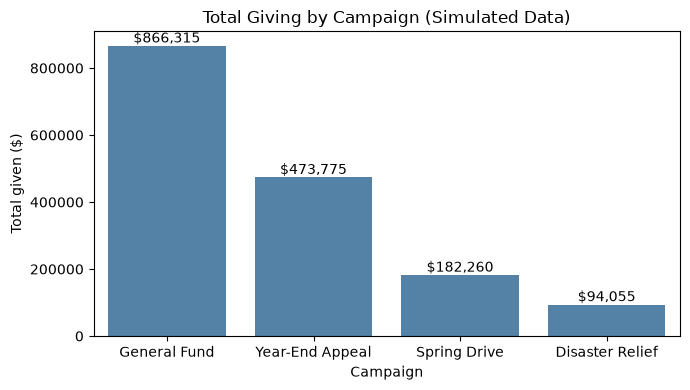

In [22]:
by_campaign = (gifts.groupby("campaign")["amount"].sum()
               .sort_values(ascending=False))
print(by_campaign.round(0))

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=by_campaign.index, y=by_campaign.values, color="steelblue")
ax.bar_label(ax.containers[0], labels=[f"${v:,.0f}" for v in by_campaign.values])
plt.title("Total Giving by Campaign (Simulated Data)")
plt.xlabel("Campaign")
plt.ylabel("Total given ($)")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/giving_by_campaign.png", dpi=200)
plt.show()

### 2.6 Giving by Month
Seasonality: total dollars (bars) and number of gifts (line) per calendar month.

       count       sum
month                 
1        512   97370.0
2        451   88915.0
3        683  103450.0
4        711  107905.0
5        710  117400.0
6        514  136485.0
7        460   83585.0
8        439  100720.0
9        522  107990.0
10       683  110815.0
11      1071  164665.0
12      2060  397105.0


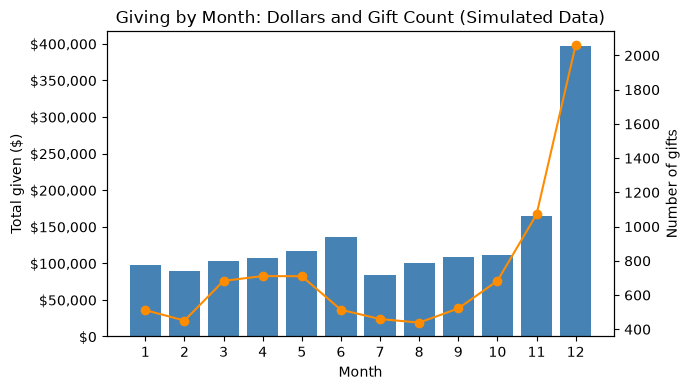

In [23]:
gifts["month"] = gifts["gift_date"].dt.month
by_month = gifts.groupby("month")["amount"].agg(["count", "sum"])
print(by_month.round(0))

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.bar(by_month.index, by_month["sum"], color="steelblue")
ax1.yaxis.set_major_formatter(lambda x, _: f"${x:,.0f}")
ax1.set_xlabel("Month")
ax1.set_ylabel("Total given ($)")
ax1.set_xticks(range(1, 13))

# Secondary axis: number of gifts
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month["count"], color="darkorange", marker="o")
ax2.set_ylabel("Number of gifts")

plt.title("Giving by Month: Dollars and Gift Count (Simulated Data)")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/giving_by_month.png", dpi=200)
plt.show()

### 2.7 Average Gift by Channel and Donor Type
Average gift size by channel, split by Individual and Corporate donors.

donor_type  Corporate  Individual
channel                          
Event          403.61      177.26
Mail           630.22      165.40
Online         496.74      145.88
Phone          360.30      145.68


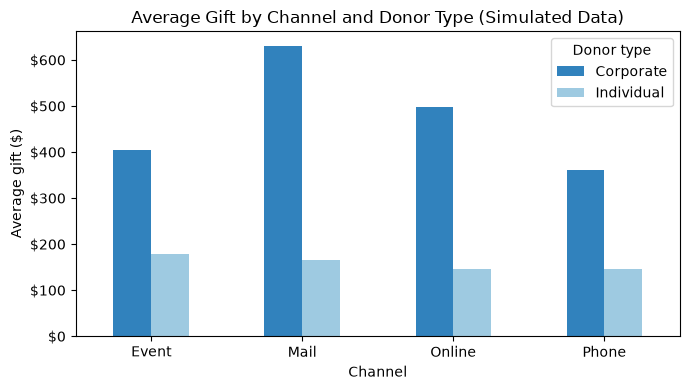

In [24]:
gd = gifts.merge(donors, on="donor_id")

avg = (gd.pivot_table(index="channel", columns="donor_type",
                      values="amount", aggfunc="mean"))
print(avg.round(2))

ax = avg.plot(kind="bar", figsize=(7, 4), color=["#3182bd", "#9ecae1"])
ax.yaxis.set_major_formatter(lambda x, _: f"${x:,.0f}")
plt.title("Average Gift by Channel and Donor Type (Simulated Data)")
plt.xlabel("Channel")
plt.ylabel("Average gift ($)")
plt.xticks(rotation=0)
plt.legend(title="Donor type")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/avg_gift_channel_type.png", dpi=200)
plt.show()

## 3. Outputs

| Output | Location |
|---|---|
| Donor table (5,000 rows) | `data/donors.csv` |
| Gift table (8,816 rows) | `data/gifts.csv` |
| Charts (6 PNG files) | `charts/` |

Next step: load the CSVs into PostgreSQL and run the three SQL files in order (`01`, `02`, `03`).

Note: All data is simulated, for learning and portfolio use.